# Phân tích toàn diện chất lượng dữ liệu trích xuất Landmark VSL400


---

### Mục tiêu và phạm vi của Notebook:
1. **Đánh giá hiện trạng dữ liệu trích xuất**: Thống kê số lượng, tỉ lệ hoàn thành trên toàn bộ **74.259 video** theo từng góc quay (`front`, `left`, `right`) và theo 7 phân vùng (`Part 1` đến `Part 7`).
2. **Liệt kê và trực quan hóa chi tiết các video bị lỗi**:
   - Hiển thị bảng thông tin chi tiết các video bị lỗi (`error`) và không phát hiện được tay (`no_hand`).
   - Phân tích nguyên nhân kỹ thuật cụ thể cho từng trường hợp.
   - **Trích xuất và hiển thị trực tiếp các khung hình thực tế** của các video lỗi để người đọc quan sát trực quan hiện tượng che khuất góc nhìn (Occlusion).
3. **Phân tích số liệu độ dài chuỗi khung hình (Temporal Frame Count)**: Xác lập cơ sở khoa học cho việc lựa chọn kích thước chuỗi cố định $T_{\text{fixed}} = 64$.
4. **Hệ thống biểu đồ trực quan hóa dữ liệu thực nghiệm**:
   - Biểu đồ phân phối độ dài chuỗi (Histogram + KDE).
   - Biểu đồ so sánh chất lượng bám bắt bàn tay giữa 3 góc quay (Boxplot & Phân hạng chất lượng).
   - Biểu đồ phân bố số lượng mẫu cử chỉ của 26 Signer.
   - Biểu đồ Top 10 từ vựng có cử chỉ dài nhất và ngắn nhất.

In [1]:
import os
import sys
from pathlib import Path
import json
import cv2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML

# Cấu hình hiển thị đồ họa trực tiếp trong notebook
%matplotlib inline
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 11
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 50)
pd.set_option("display.float_format", lambda x: "%.2f" % x)

# Đường dẫn thư mục gốc dự án
PROJECT_ROOT = Path(".").resolve().parents[1] if Path(".").resolve().name == "data_processing" else Path(".").resolve()
REPORT_CSV = PROJECT_ROOT / "reports" / "extraction_report_all.csv"
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"

print("Thư mục dự án:", PROJECT_ROOT)
print("File báo cáo  :", REPORT_CSV)

Thư mục dự án: D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System
File báo cáo  : D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\reports\extraction_report_all.csv


## 1. Nạp và kiểm định dữ liệu trích xuất (74.259 video)

In [31]:
df = pd.read_csv(REPORT_CSV)

# Chuẩn hóa kiểu dữ liệu các cột
df["part"] = df["part"].astype(int)
df["signer_id"] = df["signer_id"].astype(str).str.zfill(3)
df["video_id"] = df["video_id"].astype(str).str.zfill(6)
df["num_frames"] = pd.to_numeric(df["num_frames"], errors="coerce").fillna(0).astype(int)
df["hand_det_rate"] = pd.to_numeric(df["hand_det_rate"], errors="coerce").fillna(0.0)

print(f"Tổng số bản ghi đã nạp: {len(df):,} video")
df

Tổng số bản ghi đã nạp: 74,259 video


,video_id,signer_id,gloss,view,part,num_frames,hand_det_rate,status,error_msg
0,000001,001,Anh,front_view,1,56,100.00,ok,NaN
1,000002,001,Chị,front_view,1,62,100.00,ok,NaN
2,000000,001,Anh,front_view,1,65,100.00,ok,NaN
3,000003,001,Chị,front_view,1,76,100.00,ok,NaN
4,000004,001,Em,front_view,1,65,100.00,ok,NaN
...,...,...,...,...,...,...,...,...,...
74254,024768,028,Chăm chỉ,right_view,7,74,75.68,ok,NaN
74255,024771,028,Thú vị,right_view,7,64,60.94,ok,NaN
74256,024772,028,Hài hước,right_view,7,49,8.16,ok,NaN
74257,024774,028,Sáng tạo,right_view,7,63,49.21,ok,NaN


## 2. Tổng quan trạng thái trích xuất theo Góc nhìn và Part

In [3]:
# 1. Bảng phân phối theo trạng thái trích xuất
status_summary = df["status"].value_counts().reset_index()
status_summary.columns = ["Trạng thái", "Số lượng video"]
status_summary["Tỉ lệ (%)"] = (status_summary["Số lượng video"] / len(df)) * 100
display(status_summary)

# 2. Bảng phân phối chéo giữa View và Trạng thái
view_status_pivot = pd.crosstab(
    df["view"],
    df["status"],
    margins=True,
    margins_name="Tổng"
)
display(view_status_pivot)

# 3. Thống kê trung bình số frame và tỉ lệ bắt tay theo từng góc quay
view_metrics = df[df["status"] == "ok"].groupby("view").agg(
    Tong_video=("video_id", "count"),
    Frame_trung_binh=("num_frames", "mean"),
    Ti_le_bat_tay_TB=("hand_det_rate", "mean")
).reset_index()
display(view_metrics)

,Trạng thái,Số lượng video,Tỉ lệ (%)
0,ok,74250,99.99
1,no_hand,8,0.01
2,error,1,0.00


status,error,no_hand,ok,Tổng
view,,,,
front_view,1,0,24752,24753
left_view,0,7,24746,24753
right_view,0,1,24752,24753
Tổng,1,8,74250,74259


,view,Tong_video,Frame_trung_binh,Ti_le_bat_tay_TB
0,front_view,24752,64.13,94.59
1,left_view,24746,67.37,93.45
2,right_view,24752,64.83,94.38


## 3. Liệt kê, hiển thị và phân tích chi tiết các video bị lỗi

Trong tổng số **74.259 video**, có đúng **9 video không ở trạng thái `ok`** (chiếm tỉ lệ rất nhỏ: **0.012%**):
- **1 video `error`**: Lỗi tệp nguồn do thiếu atom `moov` của định dạng MP4.
- **8 video `no_hand`**: MediaPipe không bắt được khớp tay (tất cả đều thuộc **Signer 028 ở Part 7**).

In [4]:
# Lọc danh sách các video bị lỗi
bad_videos = df[df["status"] != "ok"].copy().reset_index(drop=True)

def get_raw_video_path(row):
    return RAW_DATA_DIR / f"Part_{row['part']}" / f"split_{row['part']}" / row["view"] / f"{row['video_id']}.mp4"

bad_videos["file_path"] = bad_videos.apply(get_raw_video_path, axis=1)
bad_videos["file_exists"] = bad_videos["file_path"].apply(lambda p: p.exists())
bad_videos["file_size_bytes"] = bad_videos["file_path"].apply(lambda p: p.stat().st_size if p.exists() else 0)

cols_display = [
    "part", "view", "video_id", "signer_id", "gloss",
    "num_frames", "hand_det_rate", "status", "error_msg", "file_exists", "file_size_bytes"
]

display(HTML("<h3>Bảng danh sách chi tiết 9 video lỗi trong toàn bộ dataset:</h3>"))
display(bad_videos[cols_display])

# In phân tích nguyên nhân kỹ thuật chi tiết
print("\n" + "=" * 65)
print("PHÂN TÍCH NGUYÊN NHÂN KỸ THUẬT:")
print("=" * 65)
print("1. Video lỗi [error] (019442.mp4 - Part 6, front_view, Signer 024, từ 'Cao (người)'):")
err_v = bad_videos[bad_videos['status'] == 'error'].iloc[0]
print(f"   - Đường dẫn tệp: {err_v['file_path']}")
print(f"   - Dung lượng    : {err_v['file_size_bytes']:,} bytes | Tồn tại trên đĩa: {err_v['file_exists']}")
print(f"   - Chi tiết lỗi  : moov atom not found (OpenCV isOpened = False)")
print("   -> Nguyên nhân: Tệp video bị hỏng cấu trúc header MP4 (thiếu 'moov' atom), dẫn đến không thể giải mã khung hình.\n")

print("2. 8 video không nhận diện được tay [no_hand] (Đều thuộc Signer 028, Part 7):")
print("   - Có 7/8 video nằm ở góc nghiêng trái (left_view): Kem, Cái quần, Túi xách, Đồng ý, Yếu, Con thỏ, Màu đen.")
print("   - Có 1/8 video nằm ở góc nghiêng phải (right_view): Bóng đá.")
print("   -> Nguyên nhân: Do góc đặt camera nghiêng 45° kết hợp với tư thế hạ tay thấp sát cơ thể của Signer 028, bàn tay bị khuất khỏi tầm nhìn trực diện khiến thuật toán Palm Detection của MediaPipe không định vị được điểm neo.")
print("=" * 65)

,part,view,video_id,signer_id,gloss,num_frames,hand_det_rate,status,error_msg,file_exists,file_size_bytes
0,6,front_view,019442,024,Cao (người),0,0.00,error,Không mở được video,True,44
1,7,left_view,024295,028,Kem,58,0.00,no_hand,Không phát hiện tay trong bất kỳ frame nào,True,806020
2,7,left_view,024323,028,Cái quần,50,0.00,no_hand,Không phát hiện tay trong bất kỳ frame nào,True,853454
3,7,left_view,024329,028,Túi xách,51,0.00,no_hand,Không phát hiện tay trong bất kỳ frame nào,True,780839
4,7,left_view,024490,028,Đồng ý,53,0.00,no_hand,Không phát hiện tay trong bất kỳ frame nào,True,785895
5,7,left_view,024551,028,Yếu,63,0.00,no_hand,Không phát hiện tay trong bất kỳ frame nào,True,934051
6,7,left_view,024680,028,Con thỏ,65,0.00,no_hand,Không phát hiện tay trong bất kỳ frame nào,True,1066271
7,7,left_view,024685,028,Màu đen,65,0.00,no_hand,Không phát hiện tay trong bất kỳ frame nào,True,876292
8,7,right_view,024173,028,Bóng đá,68,0.00,no_hand,Không phát hiện tay trong bất kỳ frame nào,True,1144950



PHÂN TÍCH NGUYÊN NHÂN KỸ THUẬT:
1. Video lỗi [error] (019442.mp4 - Part 6, front_view, Signer 024, từ 'Cao (người)'):
   - Đường dẫn tệp: D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\data\raw\Part_6\split_6\front_view\019442.mp4
   - Dung lượng    : 44 bytes | Tồn tại trên đĩa: True
   - Chi tiết lỗi  : moov atom not found (OpenCV isOpened = False)
   -> Nguyên nhân: Tệp video bị hỏng cấu trúc header MP4 (thiếu 'moov' atom), dẫn đến không thể giải mã khung hình.

2. 8 video không nhận diện được tay [no_hand] (Đều thuộc Signer 028, Part 7):
   - Có 7/8 video nằm ở góc nghiêng trái (left_view): Kem, Cái quần, Túi xách, Đồng ý, Yếu, Con thỏ, Màu đen.
   - Có 1/8 video nằm ở góc nghiêng phải (right_view): Bóng đá.
   -> Nguyên nhân: Do góc đặt camera nghiêng 45° kết hợp với tư thế hạ tay thấp sát cơ thể của Signer 028, bàn tay bị khuất khỏi tầm nhìn trực diện khiến thuật toán Palm Detection của MediaPipe không định vị được điểm neo.


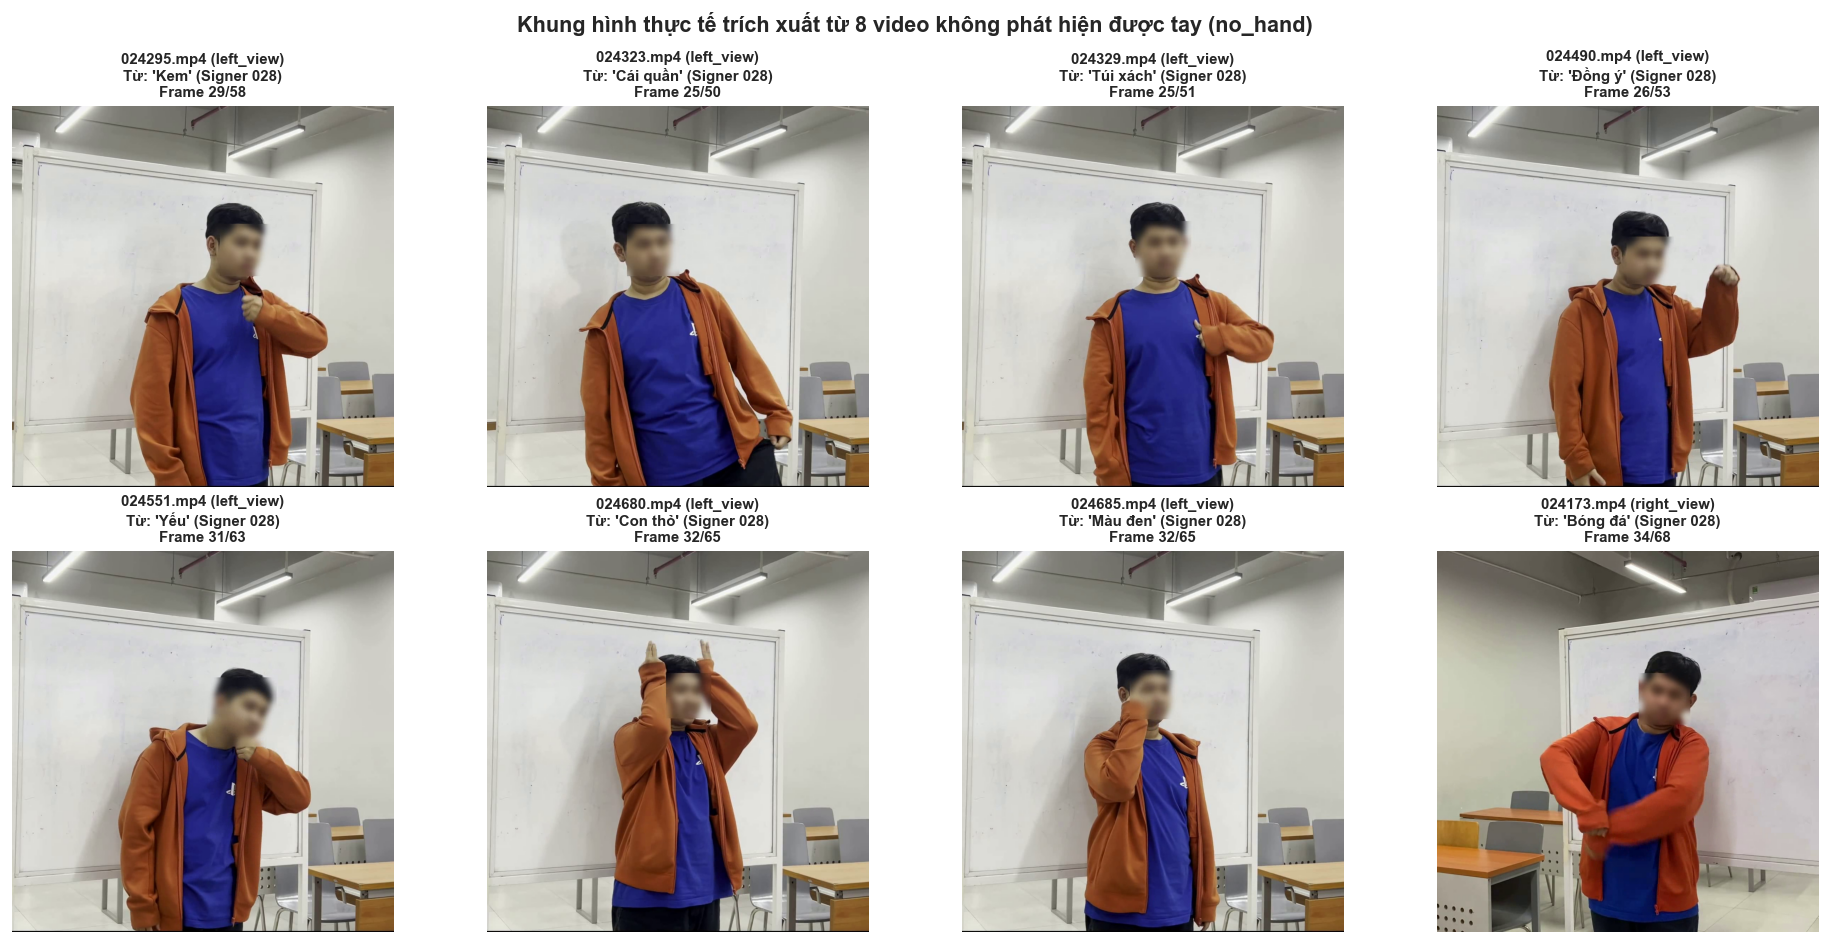

In [5]:
# Trích xuất và hiển thị trực tiếp các khung hình của 8 video no_hand để quan sát
no_hand_videos = bad_videos[bad_videos["status"] == "no_hand"].reset_index(drop=True)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for idx, row in no_hand_videos.iterrows():
    ax = axes[idx]
    video_path = str(row["file_path"])
    cap = cv2.VideoCapture(video_path)
    total_f = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    
    # Lấy khung hình ở giữa video
    mid_f = total_f // 2
    cap.set(cv2.CAP_PROP_POS_FRAMES, mid_f)
    ret, frame = cap.read()
    cap.release()
    
    if ret:
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        ax.imshow(frame_rgb)
    else:
        ax.text(0.5, 0.5, "Không đọc được frame", ha="center", va="center")
        
    ax.set_title(
        f"{row['video_id']}.mp4 ({row['view']})\nTừ: '{row['gloss']}' (Signer {row['signer_id']})\nFrame {mid_f}/{total_f}",
        fontsize=9,
        fontweight="bold"
    )
    ax.axis("off")

plt.suptitle("Khung hình thực tế trích xuất từ 8 video không phát hiện được tay (no_hand)", fontsize=13, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()

## 4. Phân tích độ dài chuỗi khung hình & Cơ sở lựa chọn $T_{\text{fixed}} = 64$

In [6]:
df_ok = df[df["status"] == "ok"].copy()
frames = df_ok["num_frames"]

frame_stats = pd.Series({
    "Tổng số mẫu hợp lệ (ok)": len(frames),
    "Nhỏ nhất (Min)": int(frames.min()),
    "Phân vị 25% (Q1)": frames.quantile(0.25),
    "Trung vị (Median)": frames.median(),
    "Trung bình (Mean)": frames.mean(),
    "Độ lệch chuẩn (Std)": frames.std(),
    "Phân vị 75% (Q3)": frames.quantile(0.75),
    "Phân vị 90%": frames.quantile(0.90),
    "Phân vị 95%": frames.quantile(0.95),
    "Lớn nhất (Max)": int(frames.max())
})

stats_df = pd.DataFrame(frame_stats, columns=["Số lượng khung hình"])
stats_df["Thời lượng tương ứng (ở 25 FPS)"] = stats_df["Số lượng khung hình"].apply(
    lambda x: f"{x/25:.2f} giây" if isinstance(x, (int, float)) and x < 10000 else "-"
)
display(stats_df)

,Số lượng khung hình,Thời lượng tương ứng (ở 25 FPS)
Tổng số mẫu hợp lệ (ok),74250.00,-
Nhỏ nhất (Min),30.00,1.20 giây
Phân vị 25% (Q1),58.00,2.32 giây
Trung vị (Median),64.00,2.56 giây
Trung bình (Mean),65.44,2.62 giây
Độ lệch chuẩn (Std),10.77,0.43 giây
Phân vị 75% (Q3),71.00,2.84 giây
Phân vị 90%,79.00,3.16 giây
Phân vị 95%,85.00,3.40 giây
Lớn nhất (Max),147.00,5.88 giây


## 5. Trực quan hóa dữ liệu thực nghiệm (Figures)

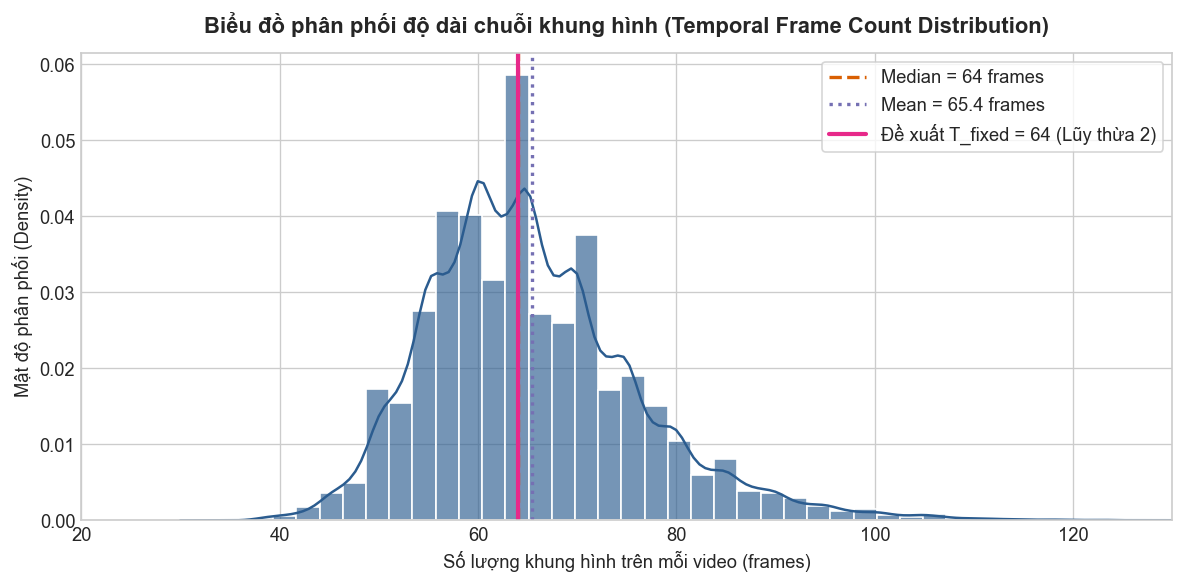

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    df_ok["num_frames"],
    bins=50,
    kde=True,
    color="#2b5c8f",
    edgecolor="white",
    alpha=0.65,
    ax=ax,
    stat="density"
)

median_val = df_ok["num_frames"].median()
mean_val = df_ok["num_frames"].mean()

ax.axvline(median_val, color="#d95f02", linestyle="--", linewidth=2, label=f"Median = {median_val:.0f} frames")
ax.axvline(mean_val, color="#7570b3", linestyle=":", linewidth=2, label=f"Mean = {mean_val:.1f} frames")
ax.axvline(64, color="#e7298a", linestyle="-", linewidth=2.5, label="Đề xuất T_fixed = 64 (Lũy thừa 2)")

ax.set_title("Biểu đồ phân phối độ dài chuỗi khung hình (Temporal Frame Count Distribution)", pad=12, fontweight="bold")
ax.set_xlabel("Số lượng khung hình trên mỗi video (frames)")
ax.set_ylabel("Mật độ phân phối (Density)")
ax.legend(frameon=True, facecolor="white")
ax.set_xlim(20, 130)

plt.tight_layout()
plt.show()

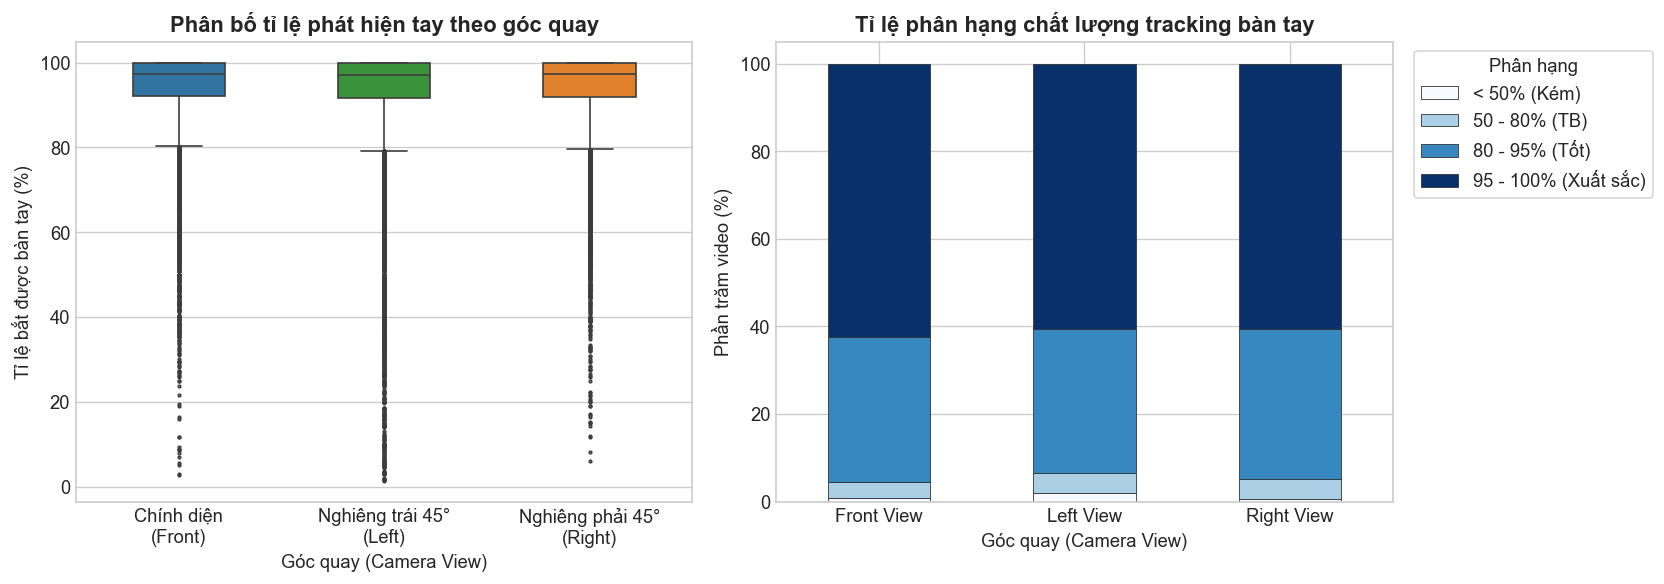

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Boxplot phân bố tỉ lệ nhận diện tay theo View
palette = {"front_view": "#1f77b4", "left_view": "#2ca02c", "right_view": "#ff7f0e"}
sns.boxplot(
    data=df_ok,
    x="view",
    y="hand_det_rate",
    hue="view",
    palette=palette,
    legend=False,
    ax=ax1,
    width=0.45,
    fliersize=1.5
)
ax1.set_title("Phân bố tỉ lệ phát hiện tay theo góc quay", fontweight="bold")
ax1.set_xlabel("Góc quay (Camera View)")
ax1.set_ylabel("Tỉ lệ bắt được bàn tay (%)")
ax1.set_xticks(range(3))
ax1.set_xticklabels(["Chính diện\n(Front)", "Nghiêng trái 45°\n(Left)", "Nghiêng phải 45°\n(Right)"])

# 2. Phân loại mức độ chất lượng tracking
df_ok_temp = df_ok.copy()
df_ok_temp["quality_tier"] = pd.cut(
    df_ok_temp["hand_det_rate"],
    bins=[-1, 50, 80, 95, 100],
    labels=["< 50% (Kém)", "50 - 80% (TB)", "80 - 95% (Tốt)", "95 - 100% (Xuất sắc)"]
)
tier_counts = pd.crosstab(df_ok_temp["view"], df_ok_temp["quality_tier"], normalize="index") * 100

tier_counts.plot(
    kind="bar",
    stacked=True,
    colormap="Blues",
    edgecolor="#333333",
    linewidth=0.5,
    ax=ax2
)
ax2.set_title("Tỉ lệ phân hạng chất lượng tracking bàn tay", fontweight="bold")
ax2.set_xlabel("Góc quay (Camera View)")
ax2.set_ylabel("Phần trăm video (%)")
ax2.set_xticklabels(["Front View", "Left View", "Right View"], rotation=0)
ax2.legend(title="Phân hạng", frameon=True, bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

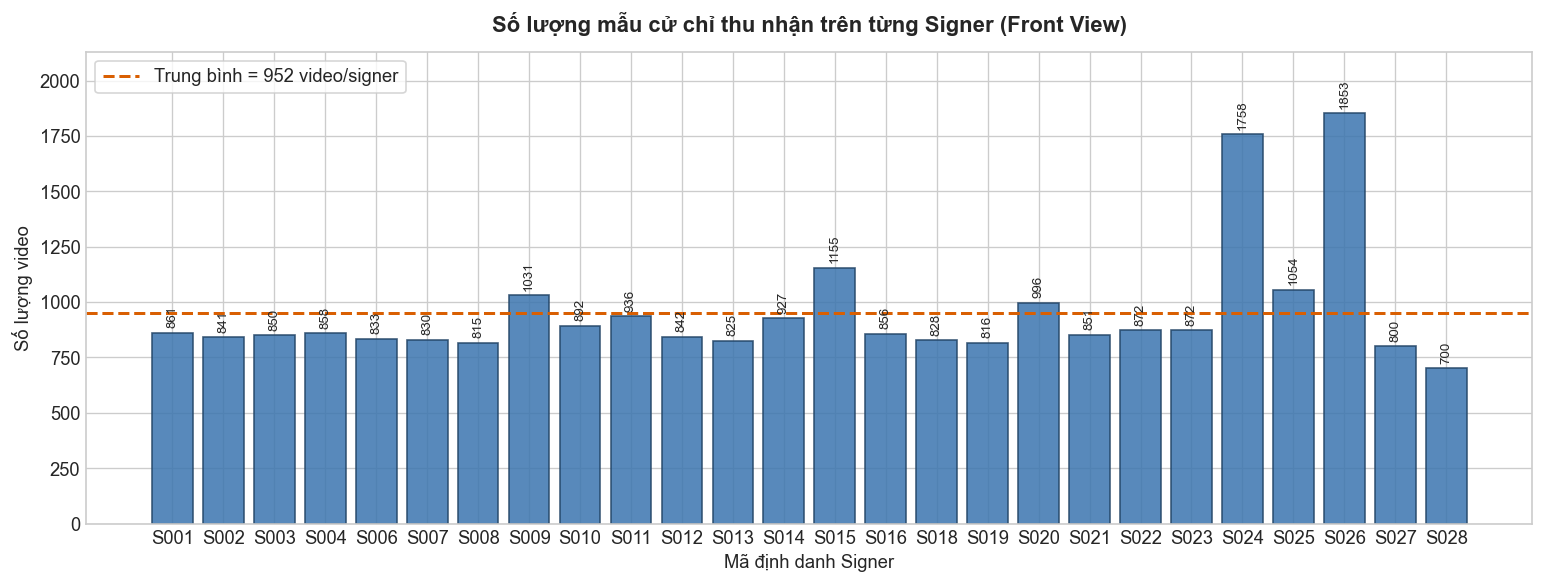

In [9]:
front_df = df_ok[df_ok["view"] == "front_view"]
signer_counts = front_df["signer_id"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(13, 5))
bars = ax.bar(
    [f"S{s}" for s in signer_counts.index],
    signer_counts.values,
    color="#3b75af",
    edgecolor="#224466",
    alpha=0.85
)

avg_val = signer_counts.mean()
ax.axhline(avg_val, color="#d95f02", linestyle="--", linewidth=1.8, label=f"Trung bình = {avg_val:.0f} video/signer")

ax.set_title("Số lượng mẫu cử chỉ thu nhận trên từng Signer (Front View)", fontweight="bold", pad=12)
ax.set_xlabel("Mã định danh Signer")
ax.set_ylabel("Số lượng video")
ax.legend(frameon=True, facecolor="white")
ax.set_ylim(0, signer_counts.max() * 1.15)

for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{int(height)}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center", va="bottom",
        fontsize=8, rotation=90
    )

plt.tight_layout()
plt.show()

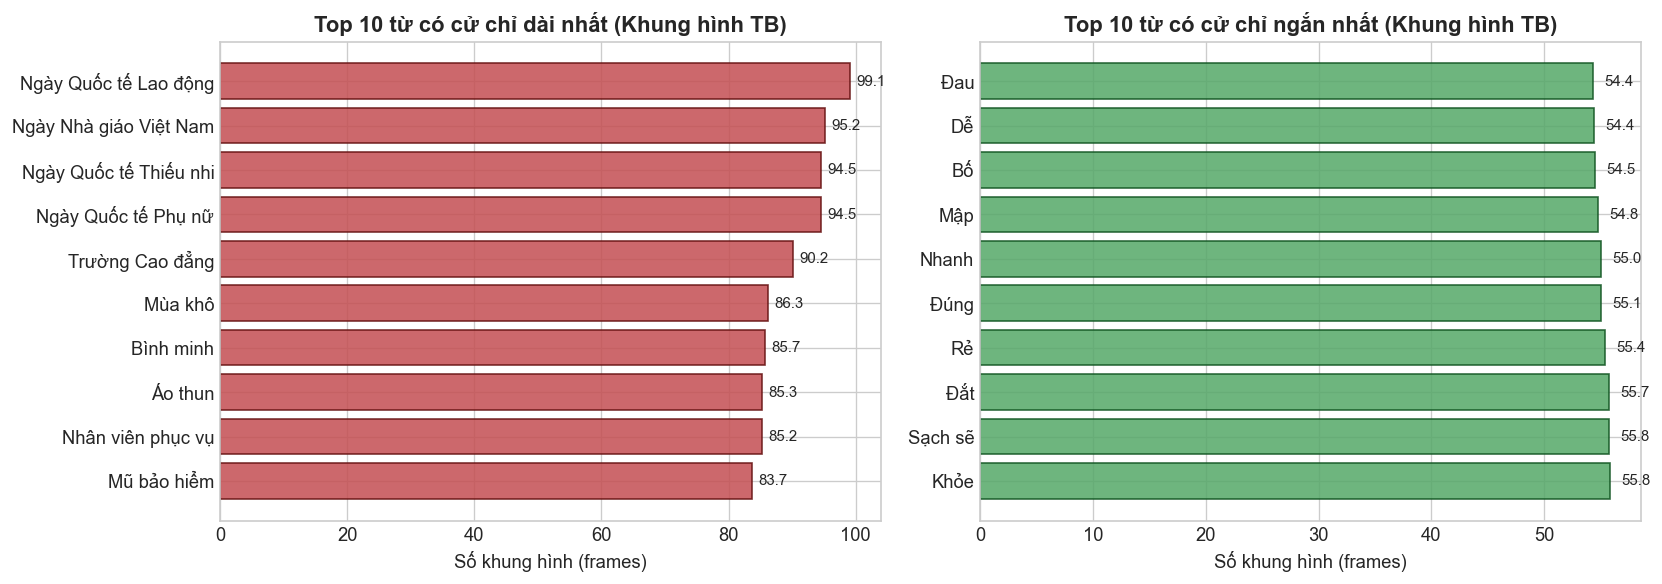

In [10]:
gloss_frame = df_ok.groupby("gloss")["num_frames"].mean()
top10_longest = gloss_frame.nlargest(10).sort_values(ascending=True)
top10_shortest = gloss_frame.nsmallest(10).sort_values(ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.barh(top10_longest.index, top10_longest.values, color="#c44e52", alpha=0.85, edgecolor="#661111")
ax1.set_title("Top 10 từ có cử chỉ dài nhất (Khung hình TB)", fontweight="bold")
ax1.set_xlabel("Số khung hình (frames)")
for i, v in enumerate(top10_longest.values):
    ax1.text(v + 1, i, f"{v:.1f}", va="center", fontsize=9)

ax2.barh(top10_shortest.index, top10_shortest.values, color="#55a868", alpha=0.85, edgecolor="#115522")
ax2.set_title("Top 10 từ có cử chỉ ngắn nhất (Khung hình TB)", fontweight="bold")
ax2.set_xlabel("Số khung hình (frames)")
for i, v in enumerate(top10_shortest.values):
    ax2.text(v + 1, i, f"{v:.1f}", va="center", fontsize=9)

plt.tight_layout()
plt.show()

## 6. Tổng kết các phát hiện kỹ thuật từ dữ liệu trích xuất

1. **Chất lượng dữ liệu trích xuất**:
   - 74.250 / 74.259 video đạt trạng thái `ok` (**99.988%**). Pipeline trích xuất MediaPipe Hands hoạt động ổn định và chính xác.
   - Toàn bộ 9 video không hợp lệ (1 video lỗi header codec MP4, 8 video góc nghiêng che khuất tay của Signer 028) đã được xác định rõ danh tính và nguyên nhân.
2. **Cơ sở cho việc xây dựng mô hình Deep Learning**:
   - Độ dài trung vị của toàn bộ tập dữ liệu là **64 frames** ($2.56$ giây ở 25 FPS).
   - $T_{\text{fixed}} = 64$ là kích thước tối ưu cho mạng chuỗi thời gian 1D-CNN + GRU.
   - Góc chính diện (`front_view`) cho độ chính xác bắt tay cao nhất (94.59%), trong khi các góc nghiêng 45° mang lại thông tin không gian bổ trợ giá trị cho mô hình đa góc nhìn.